In [ ]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt

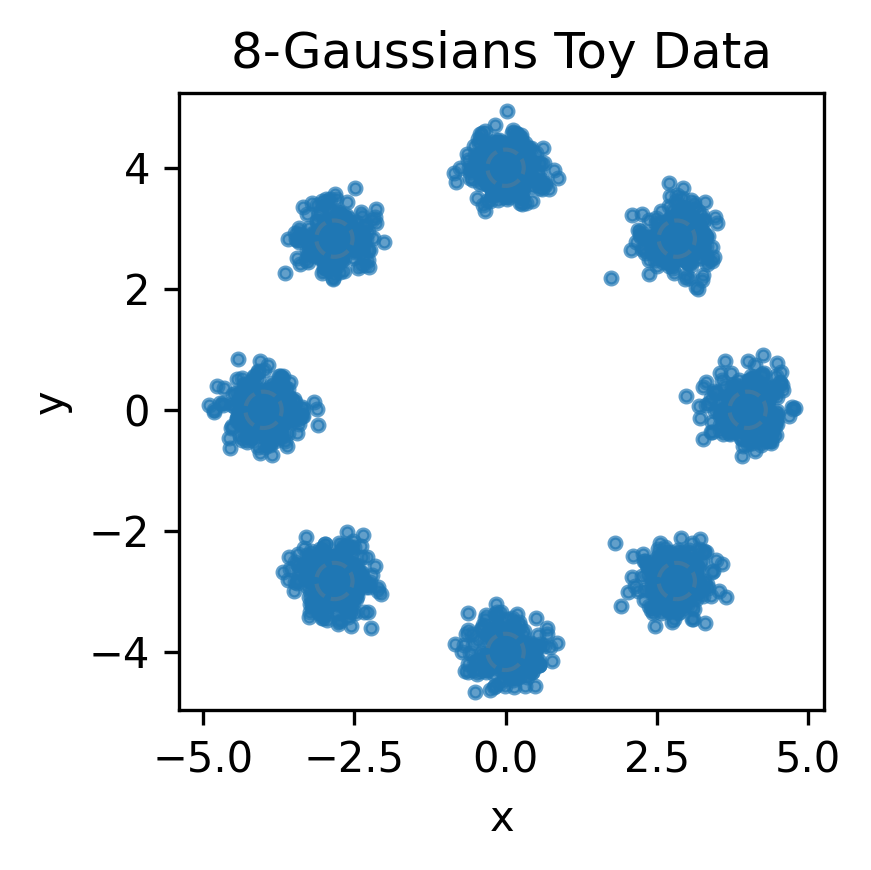

In [ ]:
# Our target is to generate the following 8-Gaussians distribution
@torch.no_grad()
def sample_8gaussians(n, radius=4.0, std=0.30, device="cpu", seed=None):
    if seed is not None:
        g = torch.Generator(device=device).manual_seed(seed)
        choice = torch.randint(0, 8, (n,), generator=g, device=device)
        eps = torch.randn(n, 2, generator=g, device=device) * std
    else:
        choice = torch.randint(0, 8, (n,), device=device)
        eps = torch.randn(n, 2, device=device) * std
    angles = (2 * math.pi / 8) * choice.float()
    centers = torch.stack([radius * torch.cos(angles), radius * torch.sin(angles)], dim=1)
    return centers + eps  # [n,2]

samples = sample_8gaussians(2000, seed=42)

# Visualization
plt.figure(figsize=(3, 3), dpi=300)
plt.scatter(samples[:, 0], samples[:, 1], s=8, alpha=0.7)
plt.xlabel("x")
plt.ylabel("y")
plt.title("8-Gaussians Toy Data")
plt.axis("equal")
for i in range(8):
    angle = 2 * math.pi * i / 8
    cx, cy = 4 * math.cos(angle), 4 * math.sin(angle)
    circle = plt.Circle((cx, cy), 0.3, color='gray', fill=False, linestyle='--', alpha=0.3)
    plt.gca().add_patch(circle)
plt.tight_layout()
plt.show()

###

We use an invertible neural map $T_\theta:\mathbb R^d\to \mathbb R^d$ to generate data as
$X=T_\theta(\xi)$ with $\xi\sim\pi_0$ (a simple base, here standard Gaussian). For maximum likelihood we evaluate

$$
\log p_\theta(x)
= \log \pi_0\bigl(T_\theta^{-1}(x)\bigr)
+\log\Bigl|\det\bigl(\nabla_x T_\theta^{-1}(x)\bigr)\Bigr|.
$$

Equivalently, if $\xi=T_\theta^{-1}(x)$, then

$$
\log p_\theta(x)
= \log \pi_0(\xi)
-\log\Bigl|\det\bigl(\nabla_\xi T_\theta(\xi)\bigr)\Bigr|.
$$

**Composition into tractable blocks**

Let the generative map be

$$
T_\theta = T_{K,\theta}\circ T_{K-1,\theta}\circ\cdots\circ T_{1,\theta}.
$$

In the generative direction,

$$
h_0=\xi,\qquad h_k=T_{k,\theta}(h_{k-1}),\quad k=1,\dots,K,\qquad x=h_K.
$$

For likelihood computations we run the inverse direction back to the base:

$$
z_K=x,\qquad z_{k-1}=T_{k,\theta}^{-1}(z_k),\quad k=K,K-1,\dots,1,\qquad z_0=\xi.
$$

Hence

$$
\log p_\theta(x)
= \log \pi_0(z_0)
+ \sum_{k=1}^K \log\Bigl|\det\bigl(\nabla T_{k,\theta}^{-1}(z_k)\bigr)\Bigr|.
$$

**Affine coupling block**

Each $T_{k,\theta}$ is an **affine coupling** transform. Split coordinates by a binary mask $m^{(k)}\in\{0,1\}^d$ into “pass-through” $u_a$ and “transformed” $u_b$. The base-to-data update is

$$
\begin{aligned}
v_a &= u_a,\\
v_b &= u_b \odot \exp\big(s_{k,\theta}(u_a)\big) + t_{k,\theta}(u_a),
\end{aligned}
$$

where $s_{k,\theta}$ and $t_{k,\theta}$ are small neural nets. The Jacobian is triangular, so

$$
\log\Bigl|\det\bigl(\nabla T_{k,\theta}(u)\bigr)\Bigr|
= \mathbf{1}^\top s_{k,\theta}(u_a).
$$

The inverse/data-to-base direction used by likelihood evaluation is

$$
\begin{aligned}
u_a &= v_a,\\
u_b &= \bigl(v_b - t_{k,\theta}(v_a)\bigr)\odot \exp\big(-s_{k,\theta}(v_a)\big),
\end{aligned}
$$

with

$$
\log\Bigl|\det\bigl(\nabla T_{k,\theta}^{-1}(v)\bigr)\Bigr|
= -\mathbf{1}^\top s_{k,\theta}(v_a).
$$

In the code below, `AffineCoupling.forward` implements this data-to-base map $T_{k,\theta}^{-1}$ because it is used inside `log_prob`, while `AffineCoupling.inverse` implements the base-to-data map $T_{k,\theta}$ used for sampling.


In [ ]:
# -------------------------
# 2) Invertible model building blocks
# T_θ : ξ -> x,  T_θ^{-1} : x -> ξ,  base π0
# self.layers stores T_1, ..., T_K in generative order.
# -------------------------

# ========== 1) Small MLP used by coupling nets ==========
class MLP(nn.Module):
    def __init__(self, in_dim, out_dim, hidden=64):
        super().__init__()
        # 2-hidden-layer MLP with ReLU
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, hidden), nn.ReLU(inplace=True),
            nn.Linear(hidden, out_dim)
        )

    def forward(self, x):
        # forward pass
        return self.net(x)


class AffineCoupling(nn.Module):
    """
    RealNVP coupling: split a vector into pass-through coordinates a and
    transformed coordinates b using a binary mask m in {0,1}^d.

    Math notation:
      T_k        : base -> data
      T_k^{-1}  : data -> base

    In this notebook, forward implements T_k^{-1} because likelihood training
    calls flow.log_prob(x), while inverse implements T_k for sampling.

    Generative/base-to-data map T_k:
      x_a = xi_a
      x_b = xi_b * exp(s(xi_a)) + t(xi_a)

    Data-to-base map T_k^{-1}:
      xi_a = x_a
      xi_b = (x_b - t(x_a)) * exp(-s(x_a))
    """
    def __init__(self, mask: torch.Tensor, hidden=64, s_clamp=3.0):
        super().__init__()
        assert mask.ndim == 1 and mask.numel() == 2, "This toy expects 2D."
        self.register_buffer("mask", mask.float())   # shape [2]
        in_dim  = int(self.mask.sum().item())        # 1
        out_dim = int((1 - self.mask).sum().item())  # 1
        self.s_net = MLP(in_dim, out_dim, hidden)
        self.t_net = MLP(in_dim, out_dim, hidden)
        self.s_clamp = float(s_clamp)

    def forward(self, x):
        """
        One step of T_k^{-1}: x -> xi, also return log|det ∂T_k^{-1}/∂x|.
        """
        # slice x_a using mask
        x_a = x[:, self.mask.bool()]
        s = self.s_net(x_a)
        t = self.t_net(x_a)
        # Clamp scale for stability: s in [-s_clamp, s_clamp]
        s = torch.tanh(s) * self.s_clamp

        xi = x.clone()
        idx_b = (~self.mask.bool())
        # inverse affine update on the "b" part: (x_b - t) * exp(-s)
        xi[:, idx_b] = (x[:, idx_b] - t) * torch.exp(-s)

        # log|det J_{T_k^{-1}}| = -sum(s) for the transformed dims
        logdet_Tinv = (-s).sum(dim=1)
        return xi, logdet_Tinv

    def inverse(self, xi):
        """
        One step of T_k: xi -> x (generative/base-to-data direction).
        """
        xi_a = xi[:, self.mask.bool()]
        s = self.s_net(xi_a)
        t = self.t_net(xi_a)
        s = torch.tanh(s) * self.s_clamp

        x = xi.clone()
        idx_b = (~self.mask.bool())
        # generative affine update on the "b" part: xi_b * exp(s) + t
        x[:, idx_b] = xi[:, idx_b] * torch.exp(s) + t
        return x

class RealNVP2D(nn.Module):
    """
    Implements T_θ via a composition of affine coupling layers.
    π0 is N(0, I_2); sampling: ξ ~ π0, x = T_θ(ξ).
    Likelihood: ξ = T_θ^{-1}(x), log p_θ(x) = log π0(ξ) + log|det ∂T_θ^{-1}(x)|.
    """
    def __init__(self, K=6, hidden=128, s_clamp=3.0):
        super().__init__()
        masks = []
        for k in range(K):
            masks.append(torch.tensor([1.0, 0.0]) if k % 2 == 0 else torch.tensor([0.0, 1.0]))
        self.layers = nn.ModuleList([AffineCoupling(m, hidden=hidden, s_clamp=s_clamp) for m in masks])

        # Base distribution π0 = N(0, I_2)
        self.register_buffer("pi0_mean", torch.zeros(2))
        self.register_buffer("pi0_cov",  torch.eye(2))
        self.pi0 = torch.distributions.MultivariateNormal(self.pi0_mean, self.pi0_cov)

    # --- Notation-aligned API ---
    def x_to_xi(self, x):
        """Compute ξ = T_θ^{-1}(x) and log|det ∂T_θ^{-1}(x)|."""
        logdet_Tinv_total = torch.zeros(x.size(0), device=x.device)
        h = x
        # T_θ = T_K ∘ ... ∘ T_1, so T_θ^{-1} applies T_K^{-1}, ..., T_1^{-1}.
        for layer in reversed(self.layers):
            h, ld = layer(h)
            logdet_Tinv_total = logdet_Tinv_total + ld
        return h, logdet_Tinv_total  # ξ, log|det|

    def xi_to_x(self, xi):
        """Compute x = T_θ(ξ) by applying T_1, ..., T_K."""
        h = xi
        # Generative/base-to-data direction.
        for layer in self.layers:
            h = layer.inverse(h)
        return h

    def _pi0(self):
        return torch.distributions.MultivariateNormal(self.pi0_mean, self.pi0_cov)

    def log_prob(self, x):
        """log p_θ(x) = log π0(ξ) + log|det ∂T_θ^{-1}(x)|."""
        xi, logdet_Tinv = self.x_to_xi(x)
        # base log-prob
        base_logp = self._pi0().log_prob(xi)
        return base_logp + logdet_Tinv

    @torch.no_grad()
    def sample(self, n, device=None):
        device = device or next(self.parameters()).device
        xi = self._pi0().sample((n,))
        return self.xi_to_x(xi)

    # --- Backward-compat wrappers (optional) ---
    def x_to_z(self, x):    # old name -> notation-aligned
        return self.x_to_xi(x)

    def z_to_x(self, z):    # old name -> notation-aligned
        return self.xi_to_x(z)


In [ ]:
def train(
    steps=5000, batch_size=512, lr=1e-3, K=6, hidden=128, s_clamp=3.0,
    device=None, log_interval=500
):
    device = device or ("cuda" if torch.cuda.is_available() else "cpu")
    torch.manual_seed(0)

    flow = RealNVP2D(K=K, hidden=hidden, s_clamp=s_clamp).to(device)
    opt = torch.optim.Adam(flow.parameters(), lr=lr)

    # Store values for the training curve
    eval_steps = []
    eval_nlls = []

    for step in range(1, steps + 1):
        x = sample_8gaussians(batch_size, device=device)

        loss = -flow.log_prob(x).mean()

        opt.zero_grad()
        loss.backward()

        nn.utils.clip_grad_norm_(
            flow.parameters(),
            max_norm=10.0
        )

        opt.step()

        if step % log_interval == 0:
            with torch.no_grad():
                nll = -flow.log_prob(
                    sample_8gaussians(2048, device=device)
                ).mean().item()

            # Save actual values from training
            eval_steps.append(step)
            eval_nlls.append(nll)

            print(
                f"[step {step:5d}] "
                f"train_NLL: {loss.item():.4f} | "
                f"eval_NLL: {nll:.4f}"
            )

    return flow, eval_steps, eval_nlls

[step   500] train_NLL: 3.3468 | eval_NLL: 3.4321
[step  1000] train_NLL: 2.8812 | eval_NLL: 2.9746
[step  1500] train_NLL: 3.0356 | eval_NLL: 2.9157
[step  2000] train_NLL: 2.9264 | eval_NLL: 2.8250
[step  2500] train_NLL: 3.0541 | eval_NLL: 3.0529
[step  3000] train_NLL: 2.8911 | eval_NLL: 2.8519
[step  3500] train_NLL: 2.7911 | eval_NLL: 2.8055
[step  4000] train_NLL: 2.7883 | eval_NLL: 2.7760
[step  4500] train_NLL: 2.7057 | eval_NLL: 2.8133
[step  5000] train_NLL: 2.7894 | eval_NLL: 2.7435


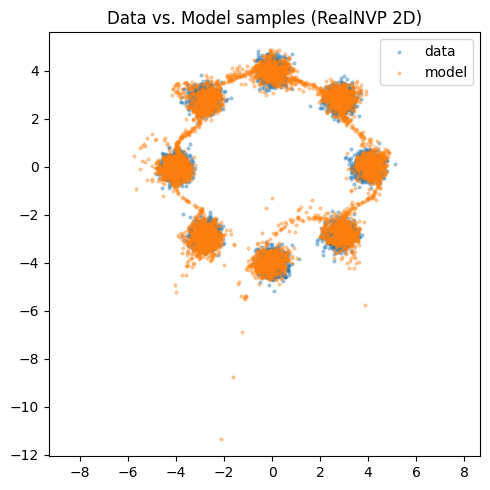

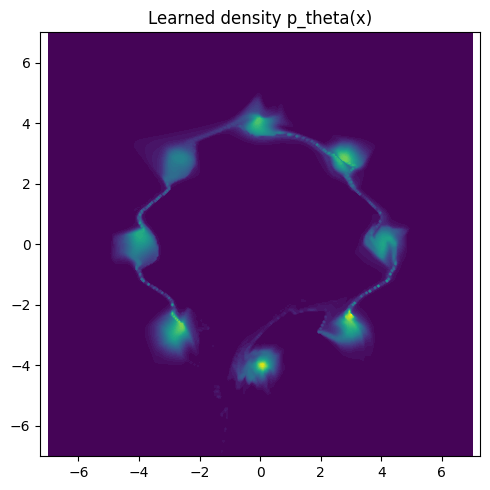

In [ ]:
# -------------------------
# 4) Visualization helpers
# -------------------------
@torch.no_grad()
def plot_scatter_data_and_model(flow, n=4000, device=None):
    device = device or next(flow.parameters()).device
    x_data = sample_8gaussians(n, device=device).cpu()
    x_model = flow.sample(n, device=device).cpu()

    plt.figure(figsize=(5, 5))
    plt.scatter(x_data[:, 0], x_data[:, 1], s=4, alpha=0.35, label="data")
    plt.scatter(x_model[:, 0], x_model[:, 1], s=4, alpha=0.35, label="model")
    plt.axis("equal")
    plt.legend()
    plt.title("Data vs. Model samples (RealNVP 2D)")
    plt.tight_layout()
    plt.show()

@torch.no_grad()
def plot_density_contour(flow, lim=7.0, grid_n=300, device=None):
    device = device or next(flow.parameters()).device
    xs = torch.linspace(-lim, lim, grid_n, device=device)
    ys = torch.linspace(-lim, lim, grid_n, device=device)
    X, Y = torch.meshgrid(xs, ys, indexing="xy")
    points = torch.stack([X.reshape(-1), Y.reshape(-1)], dim=1)

    # Chunked eval to save memory
    logp = torch.empty(points.size(0), device=device)
    chunk = 16384
    for i in range(0, points.size(0), chunk):
        logp[i:i+chunk] = flow.log_prob(points[i:i+chunk])
    Z = logp.reshape(grid_n, grid_n).exp().cpu()  # density

    plt.figure(figsize=(5, 5))
    plt.contourf(X.cpu(), Y.cpu(), Z, levels=50)
    plt.title("Learned density p_theta(x)")
    plt.axis("equal")
    plt.tight_layout()
    plt.show()



flow, eval_steps, eval_nlls = train(steps=5000, batch_size=512, lr=1e-3, K=6, hidden=128, s_clamp=3.0)
plot_scatter_data_and_model(flow, n=6000)
plot_density_contour(flow, lim=7.0, grid_n=250)

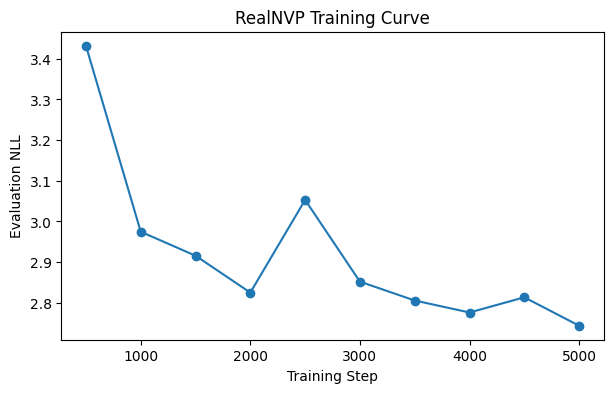


Final evaluation NLL: 2.7435


In [ ]:
plt.figure(figsize=(7, 4))

plt.plot(
    eval_steps,
    eval_nlls,
    marker="o"
)

plt.xlabel("Training Step")
plt.ylabel("Evaluation NLL")
plt.title("RealNVP Training Curve")

plt.show()
print(f"\nFinal evaluation NLL: {eval_nlls[-1]:.4f}")

### Comment on generated samples

The learned samples cover all eight modes of the target distribution. The generated samples form clusters around each of the eight Gaussian modes, although there are a few scattered samples between the modes.